# PyTorch for Biology: A Gentle, Code-First Intro

This notebook is for students with a biological background who want a fast, practical start with PyTorch. We'll use small, synthetic examples resembling gene expression and promoter detection so everything runs quickly on CPU.

In [ ]:
# Section 1: Setup and installation checks
import torch, numpy as np, random, pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

PyTorch version: 2.10.0+cpu
CUDA available: False
Using device: cpu


## 2. Tensors: creation, shapes, and dtypes
We'll start with DNA-encoded toy data (A,T,G,C mapped to 0–3) to show tensor creation, shapes, and dtypes.

In [2]:
# Small DNA example: 4 samples, 8 bases each encoded as ints 0-3
bases = np.array([
    [0,1,2,3,0,1,2,3],
    [3,3,2,2,1,1,0,0],
    [1,0,1,0,2,2,3,3],
    [2,2,1,1,0,0,3,3],
], dtype=np.int64)

tensor_from_np = torch.tensor(bases)                 # infers dtype/int64
float_tensor = torch.tensor(bases, dtype=torch.float32)
zeros = torch.zeros((2,3), dtype=torch.float32)
ones  = torch.ones((2,3), dtype=torch.float32)
rand  = torch.rand((2,3), dtype=torch.float32)

print("tensor_from_np:", tensor_from_np.shape, tensor_from_np.dtype)
print("float_tensor :", float_tensor.shape, float_tensor.dtype)
print("zeros shape   :", zeros.shape, "ones shape:", ones.shape, "rand shape:", rand.shape)

tensor_from_np: torch.Size([4, 8]) torch.int64
float_tensor : torch.Size([4, 8]) torch.float32
zeros shape   : torch.Size([2, 3]) ones shape: torch.Size([2, 3]) rand shape: torch.Size([2, 3])


## 3. Basic tensor operations (indexing, slicing, reshaping)
Think of rows as samples and columns as genes/features. We'll slice, reshape, and concatenate.

In [3]:
data = float_tensor  # from earlier cell

first_two_samples = data[:2, :]          # slicing
first_four_features = data[:, :4]
reshaped = data.view(2, 2, 8)             # reshape into (batch, chunk, features)
concat = torch.cat([data, data], dim=0)   # stack samples

print("First two samples:\n", first_two_samples)
print("First four features of all samples:\n", first_four_features)
print("Reshaped (2,2,8):", reshaped.shape)
print("Concatenated shape:", concat.shape)

# Elementwise operations
mean_per_feature = data.mean(dim=0)
std_per_feature  = data.std(dim=0)
print("Feature means:", mean_per_feature)
print("Feature stds :", std_per_feature)

First two samples:
 tensor([[0., 1., 2., 3., 0., 1., 2., 3.],
        [3., 3., 2., 2., 1., 1., 0., 0.]])
First four features of all samples:
 tensor([[0., 1., 2., 3.],
        [3., 3., 2., 2.],
        [1., 0., 1., 0.],
        [2., 2., 1., 1.]])
Reshaped (2,2,8): torch.Size([2, 2, 8])
Concatenated shape: torch.Size([8, 8])
Feature means: tensor([1.5000, 1.5000, 1.5000, 1.5000, 0.7500, 1.0000, 2.0000, 2.2500])
Feature stds : tensor([1.2910, 1.2910, 0.5774, 1.2910, 0.9574, 0.8165, 1.4142, 1.5000])


## 4. Autograd: gradients on simple functions
PyTorch tracks operations when `requires_grad=True`. Let's compute a simple mean-square and get gradients.

In [4]:
x = torch.linspace(-2, 2, steps=5, requires_grad=True)
y = (x**2).mean()  # simple function
print("y:", y.item())

y.backward()       # compute dy/dx
print("dy/dx:", x.grad)

y: 2.0
dy/dx: tensor([-0.8000, -0.4000,  0.0000,  0.4000,  0.8000])


## 5. Data handling: loading tabular biological data
We'll simulate a small gene expression table (samples × genes) and load it with pandas, then feed it to a DataLoader.

In [5]:
# Simulate a small gene expression dataset
n_samples = 200
n_genes = 20
# Healthy vs disease: disease has slightly higher expression on first 5 genes
labels = np.random.randint(0, 2, size=n_samples)
expression = np.random.normal(loc=0.0, scale=1.0, size=(n_samples, n_genes))
expression[labels == 1, :5] += 1.0  # shift disease class

# Build pandas DataFrame (for illustration of CSV-like loading)
gene_names = [f"Gene{i+1}" for i in range(n_genes)]
df = pd.DataFrame(expression, columns=gene_names)
df["label"] = labels
print(df.head())

# Convert to tensors
X = torch.tensor(df[gene_names].values, dtype=torch.float32)
y = torch.tensor(df["label"].values, dtype=torch.long)

from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X, y)
train_loader = DataLoader(dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(dataset, batch_size=64, shuffle=False)

      Gene1     Gene2     Gene3     Gene4     Gene5     Gene6     Gene7  \
0  0.087047 -0.299007  0.091761 -1.987569 -0.219672  0.357113  1.477894   
1  1.296120  1.261055  1.005113  0.765413 -0.415371 -0.420645 -0.342715   
2 -0.034712 -1.168678  1.142823  0.751933  0.791032 -0.909387  1.402794   
3 -0.783253 -0.322062  0.813517 -1.230864  0.227460  1.307143 -1.607483   
4  1.865775  0.473833 -1.191303  0.656554 -0.974682  0.787085  1.158596   

      Gene8     Gene9    Gene10  ...    Gene12    Gene13    Gene14    Gene15  \
0 -0.518270 -0.808494 -0.501757  ...  0.328751 -0.529760  0.513267  0.097078   
1 -0.802277 -0.161286  0.404051  ...  0.174578  0.257550 -0.074446 -1.918771   
2 -1.401851  0.586857  2.190456  ... -0.566298  0.099651 -0.503476 -1.550663   
3  0.184634  0.259883  0.781823  ... -1.320457  0.521942  0.296985  0.250493   
4 -0.820682  0.963376  0.412781  ...  1.896793 -0.245388 -0.753736 -0.889514   

     Gene16    Gene17    Gene18    Gene19    Gene20  label  
0  0.96

## 6. Building a simple feedforward network
We use a tiny multilayer perceptron: input → ReLU → hidden → ReLU → output (2 classes).

In [6]:
import torch.nn as nn

class ExpressionNet(nn.Module):
    def __init__(self, n_features, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2)
        )
    def forward(self, x):
        return self.net(x)

model = ExpressionNet(n_genes).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

ExpressionNet(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)
Trainable parameters: 1794


## 7. Training loop: loss, optimizer, metrics
We'll train with cross-entropy loss and Adam, tracking loss and accuracy per epoch.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

def accuracy(logits, y_true):
    preds = logits.argmax(dim=1)
    return (preds == y_true).float().mean().item()

n_epochs = 25
history = {"train_loss": [], "train_acc": []}

for epoch in range(1, n_epochs+1):
    model.train()
    total_loss, total_acc, n_batches = 0.0, 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        total_acc += accuracy(logits, yb)
        n_batches += 1
    history["train_loss"].append(total_loss / n_batches)
    history["train_acc"].append(total_acc / n_batches)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | loss {history['train_loss'][-1]:.4f} | acc {history['train_acc'][-1]:.3f}")

Epoch 05 | loss 0.1153 | acc 0.960
Epoch 10 | loss 0.0108 | acc 1.000
Epoch 15 | loss 0.0021 | acc 1.000
Epoch 20 | loss 0.0009 | acc 1.000
Epoch 25 | loss 0.0006 | acc 1.000


## 8. Toy biological task: gene-expression classification
We simulate healthy vs disease expression. Let's visualize training curves.

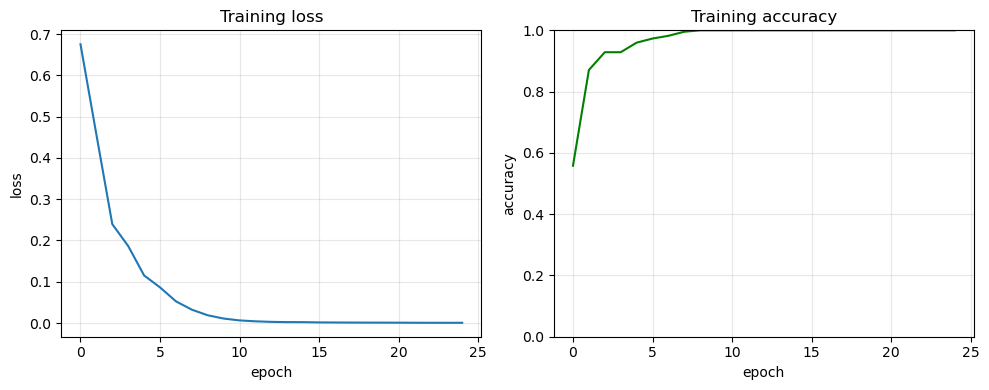

In [8]:
# Plot loss and accuracy
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="train loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)

plt.subplot(1,2,2)
plt.plot(history["train_acc"], label="train acc", color="green")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Training accuracy")
plt.ylim(0,1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Quick inference on a few samples
Let's inspect predictions on 5 random samples.

In [9]:
model.eval()
with torch.no_grad():
    sample_idx = np.random.choice(n_samples, size=5, replace=False)
    sample_x = X[sample_idx].to(device)
    sample_y = y[sample_idx]
    logits = model(sample_x)
    probs = torch.softmax(logits, dim=1)[:,1].cpu().numpy()
    preds = logits.argmax(dim=1).cpu().numpy()

for i, idx in enumerate(sample_idx):
    print(f"Sample {idx:3d} | true label: {sample_y[i].item()} | pred: {preds[i]} | p(disease)={probs[i]:.3f}")

Sample  28 | true label: 1 | pred: 1 | p(disease)=0.997
Sample  93 | true label: 1 | pred: 1 | p(disease)=1.000
Sample   2 | true label: 0 | pred: 0 | p(disease)=0.001
Sample 171 | true label: 0 | pred: 0 | p(disease)=0.000
Sample  69 | true label: 1 | pred: 1 | p(disease)=1.000


## 9. Saving and loading models
Persist model weights with `state_dict`; reload to continue training or run inference later.

In [10]:
ckpt_path = "expression_net.pt"
torch.save(model.state_dict(), ckpt_path)
print(f"Saved to {ckpt_path}")

# Load into a fresh model
loaded_model = ExpressionNet(n_genes).to(device)
loaded_model.load_state_dict(torch.load(ckpt_path, map_location=device))
loaded_model.eval()

# Verify a quick prediction matches shape
with torch.no_grad():
    test_logits = loaded_model(X[:2].to(device))
    print("Loaded model logits shape:", test_logits.shape)

Saved to expression_net.pt
Loaded model logits shape: torch.Size([2, 2])


/tmp/ipykernel_822106/237955992.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model.load_state_dict(torch.load(ckpt_path, map_location=device))
